
# Week 3 – Seoul Bike Sharing: Simulation vs Observation

**Goal:** Connect our Week 2 simulation to real hourly observations and compare simulated and measured bicycle rentals.

We use a chronological 80/20 split:
- First 80%: Calculate average hourly rental demand.
- Last 20%: Evaluate the simulation using previously unseen observations.

The actual rental counts in the evaluation period are not used to generate simulated values.

This is a simple hourly baseline simulation, not a machine-learning model or a fully dynamic state model.


In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# CSV is located in the repository root
csv_path = Path("../SeoulBikeData.csv")

# Also works if notebook is executed from the root folder
if not csv_path.exists():
    csv_path = Path("SeoulBikeData.csv")

df = pd.read_csv(csv_path, encoding="latin1")

print("Number of rows:", len(df))
print("Columns:", df.columns.tolist())

df.head()

Number of rows: 8760
Columns: ['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day']


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


## 1. Data Preparation

Create timestamps from the Date and Hour columns.

Check for missing values and duplicate timestamps before cleaning the dataset.

In [5]:
df["Timestamp"] = (
    pd.to_datetime(df["Date"], dayfirst=True)
    + pd.to_timedelta(df["Hour"], unit="h")
)

df = df.sort_values("Timestamp").reset_index(drop=True)

print("Missing values:")
print(df.isna().sum())

print("Duplicate timestamps:", df["Timestamp"].duplicated().sum())

print("Start:", df["Timestamp"].min())
print("End:", df["Timestamp"].max())

Missing values:
Date                         0
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Functioning Day              0
Timestamp                    0
dtype: int64
Duplicate timestamps: 0
Start: 2017-12-01 00:00:00
End: 2018-11-30 23:00:00


In [6]:
columns = [
    "Timestamp",
    "Hour",
    "Temperature(°C)",
    "Humidity(%)",
    "Rainfall(mm)",
    "Wind speed (m/s)",
    "Functioning Day",
    "Rented Bike Count"
]

data = df[columns].dropna().copy()

data = data.drop_duplicates(subset="Timestamp")

data = data[
    (data["Rented Bike Count"] >= 0)
    & data["Hour"].between(0, 23)
    & data["Humidity(%)"].between(0, 100)
    & (data["Rainfall(mm)"] >= 0)
    & (data["Wind speed (m/s)"] >= 0)
]

data = data.sort_values("Timestamp").reset_index(drop=True)

print("Clean rows:", len(data))

data.head()

Clean rows: 8760


,Timestamp,Hour,Temperature(°C),Humidity(%),Rainfall(mm),Wind speed (m/s),Functioning Day,Rented Bike Count
0,2017-12-01 00:00:00,0,-5.2,37,0.0,2.2,Yes,254
1,2017-12-01 01:00:00,1,-5.5,38,0.0,0.8,Yes,204
2,2017-12-01 02:00:00,2,-6.0,39,0.0,1.0,Yes,173
3,2017-12-01 03:00:00,3,-6.2,40,0.0,0.9,Yes,107
4,2017-12-01 04:00:00,4,-6.0,36,0.0,2.3,Yes,78


## 2. Historical Observations

Plot the measured number of bicycle rentals over time.

The observation variable is `Rented Bike Count`, measured in bicycles per hour.

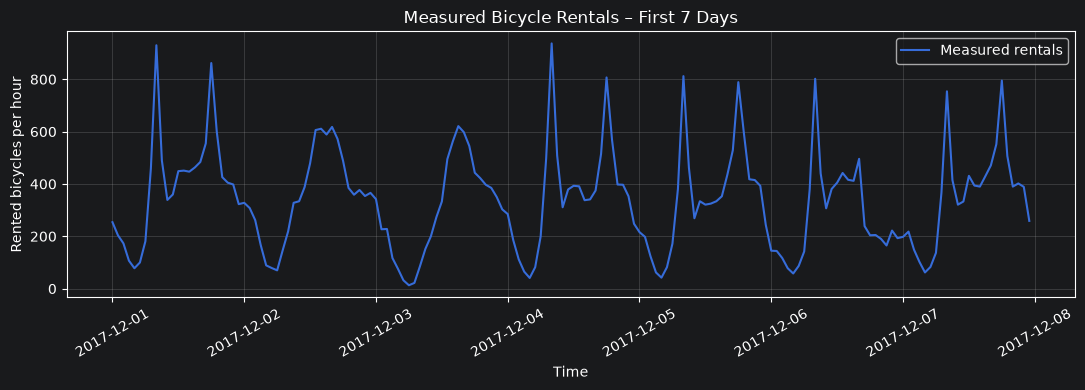

In [7]:
observed_week = data.head(24 * 7)

plt.figure(figsize=(11, 4))

plt.plot(
    observed_week["Timestamp"],
    observed_week["Rented Bike Count"],
    label="Measured rentals"
)

plt.title("Measured Bicycle Rentals – First 7 Days")
plt.xlabel("Time")
plt.ylabel("Rented bicycles per hour")

plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 3. Training and Evaluation Data

Split the dataset chronologically:

- 80% for calculating the hourly rental baseline.
- 20% for comparing simulated and measured rentals

Only the training period is used to calculate the hourly averages.

The evaluation period's actual rental counts are reserved for comparison.

In [8]:
split_index = int(len(data) * 0.8)

train = data.iloc[:split_index].copy()
test = data.iloc[split_index:].copy()

print("Training rows:", len(train))
print("Evaluation rows:", len(test))

print("Evaluation starts:", test["Timestamp"].min())
print("Evaluation ends:", test["Timestamp"].max())

Training rows: 7008
Evaluation rows: 1752
Evaluation starts: 2018-09-19 00:00:00
Evaluation ends: 2018-11-30 23:00:00


Average rentals by hour:
Hour
0      541.1
1      426.6
2      304.1
3      204.4
4      133.6
5      143.6
6      294.1
7      607.6
8     1004.5
9      639.5
10     517.3
11     590.9
12     686.0
13     711.2
14     728.2
15     793.6
16     894.7
17    1105.2
18    1487.0
19    1202.2
20    1086.4
21    1051.7
22     935.6
23     679.3
Name: Rented Bike Count, dtype: float64


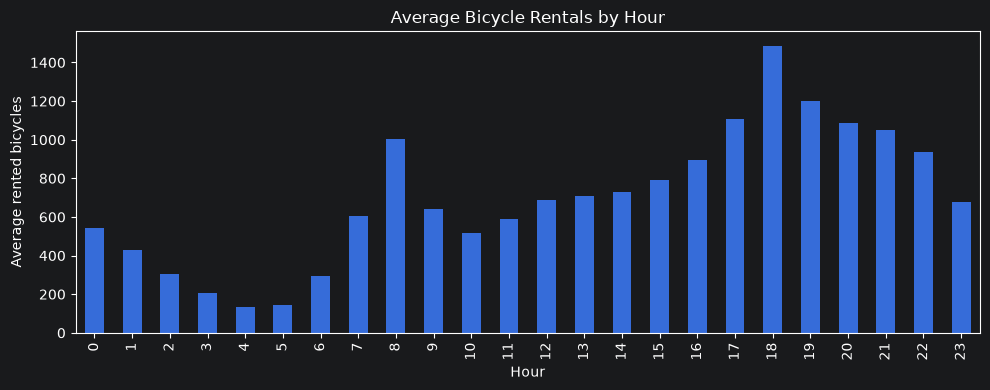

In [9]:
# Only operating days are used for the baseline
operating_train = train[
    train["Functioning Day"] == "Yes"
]

hourly_average = operating_train.groupby("Hour")[
    "Rented Bike Count"
].mean()

print("Average rentals by hour:")
print(hourly_average.round(1))

hourly_average.plot(
    kind="bar",
    figsize=(10, 4),
    title="Average Bicycle Rentals by Hour"
)

plt.xlabel("Hour")
plt.ylabel("Average rented bicycles")
plt.tight_layout()
plt.show()

## 4. Simulation Model

The simulation uses the average rental count for each hour as a baseline.

The baseline is modified using weather conditions and service availability.

We reuse the illustrative weather-effect coefficients from Week 2:

- Temperature: -1.5% per °C increase
- Humidity: -0.4% per percentage point increase
- Rainfall: -6% per mm increase
- Wind speed: -3% per m/s increase

For this simulation, the reference conditions are:
- Temperature: 15 °C
- Humidity: 60%
- Rainfall: 0 mm
- Wind speed: 0 m/s

These coefficients and reference conditions are modelling assumptions, not calibrated relationships.

When the service is unavailable, completed rentals are zero.

In [19]:
def simulate_bikes(row):
    # Baseline for the current hour
    baseline = hourly_average.loc[row["Hour"]]

    # Differences from reference conditions
    temperature_change = row["Temperature(°C)"] - 20
    humidity_change = row["Humidity(%)"] - 30
    rainfall = row["Rainfall(mm)"]
    wind = row["Wind speed (m/s)"]

    # Illustrative weather effects from Week 2
    factor = (
        1
        - 0.015 * temperature_change
        - 0.004 * humidity_change
        - 0.06 * rainfall
        - 0.03 * wind
    )

    # Avoid negative rental demand
    factor = max(0, factor)

    # No completed rentals if service is unavailable
    if row["Functioning Day"] == "No":
        return 0

    simulated = baseline * factor

    return round(max(0, simulated))

In [20]:
test["Simulated Rented Bike Count"] = test.apply(
    simulate_bikes,
    axis=1
)

test[
    [
        "Timestamp",
        "Hour",
        "Rented Bike Count",
        "Simulated Rented Bike Count"
    ]
].head(10)


,Timestamp,Hour,Rented Bike Count,Simulated Rented Bike Count
7008,2018-09-19 00:00:00,0,0,0
7009,2018-09-19 01:00:00,1,0,0
7010,2018-09-19 02:00:00,2,0,0
7011,2018-09-19 03:00:00,3,0,0
7012,2018-09-19 04:00:00,4,0,0
7013,2018-09-19 05:00:00,5,0,0
7014,2018-09-19 06:00:00,6,0,0
7015,2018-09-19 07:00:00,7,0,0
7016,2018-09-19 08:00:00,8,0,0
7017,2018-09-19 09:00:00,9,0,0


## 5. Simulation vs Observation

Compare simulated and measured bicycle rentals over the same time period.

Both values are measured in bicycles per hour.

The chart shows the first seven days of the evaluation period.

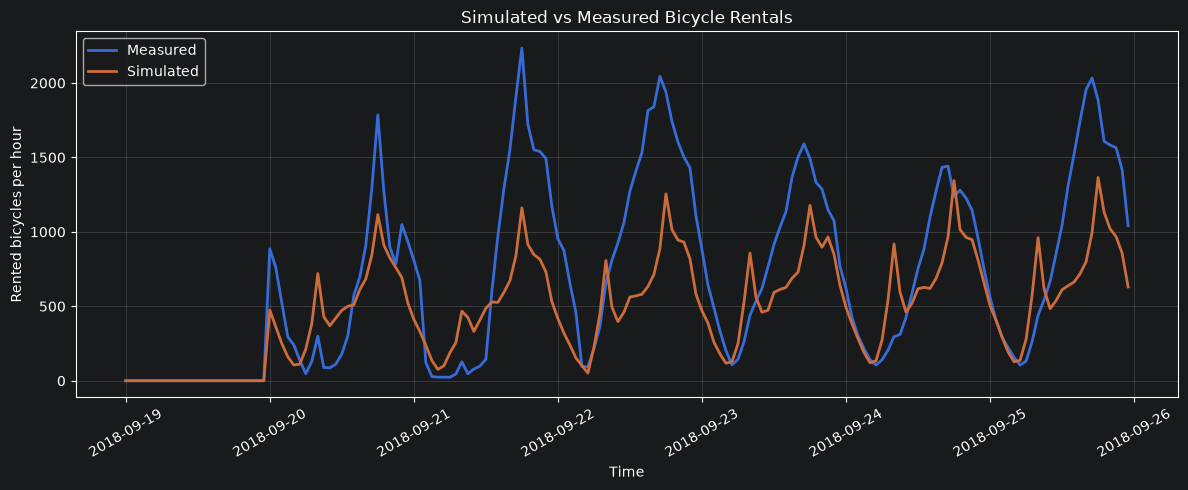

In [21]:
comparison = test.head(24 * 7)

plt.figure(figsize=(12, 5))

plt.plot(
    comparison["Timestamp"],
    comparison["Rented Bike Count"],
    label="Measured",
    linewidth=2
)

plt.plot(
    comparison["Timestamp"],
    comparison["Simulated Rented Bike Count"],
    label="Simulated",
    linewidth=2
)

plt.title("Simulated vs Measured Bicycle Rentals")
plt.xlabel("Time")
plt.ylabel("Rented bicycles per hour")

plt.xticks(rotation=30)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
absolute_error = (
    test["Simulated Rented Bike Count"]
    - test["Rented Bike Count"]
).abs()

mae = absolute_error.mean()

print(f"Mean Absolute Error: {mae:.2f} bicycles/hour")

Mean Absolute Error: 289.58 bicycles/hour


## 6. Discussion

The simulation captures the general hourly rental pattern using average demand and weather conditions.

However, simulated and measured values may differ because:

- Weather-effect coefficients are assumptions.
- The model uses historical hourly averages.
- Seasonal changes are not explicitly modelled.
- Holidays and other factors may influence rental demand.
- The current simulation does not use the previous demand state.

No parameter calibration or automatic synchronization has been implemented.

## 7. Preparation for Week 4

**1. Which measured variable should synchronize the Digital Twin?**

`Rented Bike Count`, measured in bicycles per hour.

**2. How frequently should the model be updated?**

Every hour, matching the dataset's time resolution.

**3. How would the next time step be predicted after synchronization?**

A new hourly observation could be used to update the model's estimated demand state. The next hour's demand would then be calculated using the updated state, the next hour and the expected weather conditions.

This synchronization is a proposed future extension and is not implemented in Week 3.

**Limitation:** Completed rentals do not directly measure latent demand. When the service is unavailable, recorded rentals are zero even if potential demand exists.